In [ ]:

import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU Memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
else:
    raise RuntimeError("GPU is not connected!")


PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
CUDA available: True
GPU: Tesla T4
GPU Memory: 14.56 GB


In [ ]:

import os
import json
import random
import time
import zipfile
import urllib.request
import copy
import shutil

from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

torch.backends.cudnn.benchmark = True

DEVICE = torch.device("cuda")

ROOT = Path("/content/human_pose_project")

IMG_DIR = ROOT / "val2017"
ANN_DIR = ROOT / "annotations"

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 5

MAX_TRAIN_IMAGES = 200
MAX_VAL_IMAGES = 50
MAX_TEST_IMAGES = 50

NUM_WORKERS = 2

ROOT.mkdir(parents=True, exist_ok=True)
IMG_DIR.mkdir(parents=True, exist_ok=True)
ANN_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("Project configuration completed!")


Device: cuda
Project configuration completed!


In [ ]:

import urllib.request
import zipfile
import shutil

ann_zip = ROOT / "annotations_trainval2017.zip"

url = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"

if not ann_zip.exists():
    print("Downloading COCO annotations...")

    urllib.request.urlretrieve(url, ann_zip)

keypoint_json = ANN_DIR / "person_keypoints_val2017.json"

if not keypoint_json.exists():

    with zipfile.ZipFile(ann_zip, "r") as z:
        z.extract(
            "annotations/person_keypoints_val2017.json",
            ROOT
        )

    extracted = ROOT / "annotations/person_keypoints_val2017.json"

    print("Annotations extracted!")

with open(keypoint_json, "r") as f:
    coco_data = json.load(f)

print("COCO dataset loaded!")
print("Images:", len(coco_data["images"]))
print("Annotations:", len(coco_data["annotations"]))


Annotations extracted!
COCO dataset loaded!
Images: 5000
Annotations: 11004


In [ ]:

anns_by_image = defaultdict(list)

for ann in coco_data["annotations"]:

    if ann["category_id"] == 1 and ann["num_keypoints"] >= 5:
        anns_by_image[ann["image_id"]].append(ann)

image_info = {
    img["id"]: img
    for img in coco_data["images"]
}

eligible_ids = [
    image_id for image_id in image_info
    if image_id in anns_by_image
]

random.shuffle(eligible_ids)

train_ids = eligible_ids[:200]
val_ids = eligible_ids[200:250]
test_ids = eligible_ids[250:300]

print("Training images:", len(train_ids))
print("Validation images:", len(val_ids))
print("Testing images:", len(test_ids))


Training images: 200
Validation images: 50
Testing images: 50


In [ ]:
import random

random.seed(42)

all_ids = eligible_ids.copy()
random.shuffle(all_ids)

train_ids = all_ids[:500]
val_ids = all_ids[500:600]
test_ids = all_ids[600:700]

print("Training images:", len(train_ids))
print("Validation images:", len(val_ids))
print("Testing images:", len(test_ids))

print("Training person samples:",
      sum(len(anns_by_image[i]) for i in train_ids))

print("Validation person samples:",
      sum(len(anns_by_image[i]) for i in val_ids))

print("Testing person samples:",
      sum(len(anns_by_image[i]) for i in test_ids))

Training images: 500
Validation images: 100
Testing images: 100
Training person samples: 1313
Validation person samples: 248
Testing person samples: 265


In [ ]:
import torch
from torch.utils.data import Dataset
from PIL import Image
from pathlib import Path
import numpy as np

IMAGE_DIR = ROOT / "val2017"

class PoseDataset(Dataset):
    def __init__(self, image_ids, transform=None):
        self.samples = []
        self.transform = transform

        for image_id in image_ids:
            img_info = image_info[image_id]

            for ann in anns_by_image[image_id]:
                self.samples.append((img_info, ann))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_info, ann = self.samples[idx]

        image_path = IMAGE_DIR / img_info["file_name"]
        image = Image.open(image_path).convert("RGB")

        x, y, w, h = ann["bbox"]

        # Add a small margin around the person
        margin = 0.1
        x1 = max(0, int(x - margin * w))
        y1 = max(0, int(y - margin * h))
        x2 = min(image.width, int(x + w * (1 + margin)))
        y2 = min(image.height, int(y + h * (1 + margin)))

        image = image.crop((x1, y1, x2, y2))
        image = image.resize((224, 224))

        # COCO keypoints: 17 x (x, y, visibility)
        keypoints = np.array(ann["keypoints"], dtype=np.float32).reshape(17, 3)

        # Normalize coordinates relative to the crop
        keypoints[:, 0] = (keypoints[:, 0] - x1) / max(x2 - x1, 1)
        keypoints[:, 1] = (keypoints[:, 1] - y1) / max(y2 - y1, 1)

        # Keep coordinates in the range [0, 1]
        keypoints[:, :2] = np.clip(keypoints[:, :2], 0, 1)

        coords = torch.tensor(keypoints[:, :2], dtype=torch.float32)
        visibility = torch.tensor(
            (keypoints[:, 2] > 0).astype(np.float32)
        )

        if self.transform:
            image = self.transform(image)

        return image, coords, visibility


print("PoseDataset class created successfully!")

PoseDataset class created successfully!


In [ ]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = PoseDataset(train_ids, transform)
val_dataset = PoseDataset(val_ids, transform)
test_dataset = PoseDataset(test_ids, transform)

print("Training person samples:", len(train_dataset))
print("Validation person samples:", len(val_dataset))
print("Testing person samples:", len(test_dataset))

Training person samples: 1313
Validation person samples: 248
Testing person samples: 265


In [ ]:
print("Image directory:", IMAGE_DIR)
print("Folder exists:", IMAGE_DIR.exists())

if IMAGE_DIR.exists():
    files = list(IMAGE_DIR.glob("*.jpg"))
    print("Number of downloaded images:", len(files))
else:
    print("Image folder does not exist!")

Image directory: /content/human_pose_project/val2017
Folder exists: True
Number of downloaded images: 300


In [ ]:
import requests
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

selected_ids = train_ids + val_ids + test_ids

filenames = list({
    image_info[i]["file_name"] for i in selected_ids
})

def download_image(filename):
    path = IMAGE_DIR / filename

    if path.exists() and path.stat().st_size > 0:
        return True

    url = f"http://images.cocodataset.org/val2017/{filename}"

    for attempt in range(3):
        try:
            response = requests.get(url, timeout=30)
            response.raise_for_status()

            if len(response.content) > 1000:
                path.write_bytes(response.content)
                return True

        except requests.RequestException:
            continue

    return False

with ThreadPoolExecutor(max_workers=8) as executor:
    results_download = list(tqdm(
        executor.map(download_image, filenames),
        total=len(filenames)
    ))

print("Downloaded successfully:", sum(results_download))
print("Failed:", results_download.count(False))

  0%|          | 0/700 [00:00<?, ?it/s]

Downloaded successfully: 700
Failed: 0


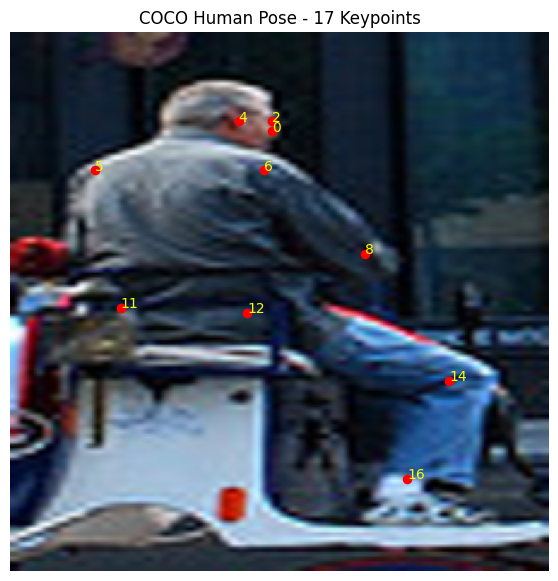

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Get one sample
image, coords, visibility = train_dataset[0]

# Convert normalized image back to display format
img = image.permute(1, 2, 0).numpy()
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
img = np.clip(img * std + mean, 0, 1)

# Display image and keypoints
plt.figure(figsize=(7, 7))
plt.imshow(img)

for i in range(17):
    if visibility[i] > 0:
        x, y = coords[i]
        plt.scatter(x * 224, y * 224, c="red", s=35)
        plt.text(x * 224, y * 224, str(i), color="yellow")

plt.title("COCO Human Pose - 17 Keypoints")
plt.axis("off")
plt.show()

In [ ]:
train_dataset = PoseDataset(train_ids, transform)
val_dataset = PoseDataset(val_ids, transform)
test_dataset = PoseDataset(test_ids, transform)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 1313
Validation samples: 248
Testing samples: 265


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import random
import os

from pathlib import Path

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

EPOCHS = 5
LEARNING_RATE = 0.0001
NUM_KEYPOINTS = 17

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Device: cuda
GPU: Tesla T4


In [ ]:
EPOCHS = 20
LEARNING_RATE = 0.0001

print("Epochs per model:", EPOCHS)
print("Total models:", 3)

Epochs per model: 20
Total models: 3


In [ ]:
model_names = [
    "MobileNetV3",
    "ResNet18",
    "EfficientNetB0"
]

trained_models = {}
training_history = {}
training_times = {}

os.makedirs("pose_checkpoints", exist_ok=True)

for name in model_names:

    print("\n" + "=" * 50)
    print("Training:", name)
    print("=" * 50)

    model = PoseModel(name).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=1e-4
    )

    history = {
        "train_loss": [],
        "val_loss": []
    }

    start_time = time.time()

    for epoch in range(EPOCHS):

        train_loss = train_one_epoch(
            model, train_loader, optimizer
        )

        val_loss = validate_one_epoch(
            model, val_loader
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        print(
            f"Epoch [{epoch+1}/{EPOCHS}] "
            f"Train Loss: {train_loss:.4f} "
            f"Val Loss: {val_loss:.4f}"
        )

    elapsed = time.time() - start_time

    training_times[name] = elapsed
    training_history[name] = history
    trained_models[name] = model

    torch.save(
        model.state_dict(),
        f"pose_checkpoints/{name}.pth"
    )

    print(f"{name} completed in {elapsed/60:.2f} minutes")

print("\nAll models trained successfully!")


Training: MobileNetV3
Epoch [1/20] Train Loss: 0.6651 Val Loss: 0.5737
Epoch [2/20] Train Loss: 0.5615 Val Loss: 0.5363
Epoch [3/20] Train Loss: 0.5125 Val Loss: 0.4878
Epoch [4/20] Train Loss: 0.4765 Val Loss: 0.4647
Epoch [5/20] Train Loss: 0.4506 Val Loss: 0.4534
Epoch [6/20] Train Loss: 0.4270 Val Loss: 0.4461
Epoch [7/20] Train Loss: 0.4117 Val Loss: 0.4430
Epoch [8/20] Train Loss: 0.3945 Val Loss: 0.4458
Epoch [9/20] Train Loss: 0.3791 Val Loss: 0.4500
Epoch [10/20] Train Loss: 0.3651 Val Loss: 0.4511
Epoch [11/20] Train Loss: 0.3550 Val Loss: 0.4493
Epoch [12/20] Train Loss: 0.3443 Val Loss: 0.4468
Epoch [13/20] Train Loss: 0.3359 Val Loss: 0.4545
Epoch [14/20] Train Loss: 0.3288 Val Loss: 0.4511
Epoch [15/20] Train Loss: 0.3176 Val Loss: 0.4598
Epoch [16/20] Train Loss: 0.3157 Val Loss: 0.4609
Epoch [17/20] Train Loss: 0.3078 Val Loss: 0.4624
Epoch [18/20] Train Loss: 0.3023 Val Loss: 0.4687
Epoch [19/20] Train Loss: 0.2965 Val Loss: 0.4630
Epoch [20/20] Train Loss: 0.2879 Val

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import torch
import time

def evaluate_model(model, loader):

    model.eval()

    all_distances = []
    all_true_visibility = []
    all_pred_visibility = []

    total_inference_time = 0
    total_samples = 0

    with torch.no_grad():

        for images, coords, visibility in loader:

            images = images.to(device)
            coords = coords.to(device)
            visibility = visibility.to(device)

            if device.type == "cuda":
                torch.cuda.synchronize()

            start = time.perf_counter()

            pred_coords, pred_visibility = model(images)

            if device.type == "cuda":
                torch.cuda.synchronize()

            total_inference_time += time.perf_counter() - start
            total_samples += images.size(0)

            distances = torch.sqrt(
                ((pred_coords - coords) ** 2).sum(dim=-1)
            )

            mask = visibility > 0

            all_distances.extend(
                distances[mask].cpu().numpy()
            )

            pred_vis = (pred_visibility >= 0).int()

            all_true_visibility.extend(
                visibility.int().cpu().numpy().flatten()
            )

            all_pred_visibility.extend(
                pred_vis.cpu().numpy().flatten()
            )

    distances = np.array(all_distances)

    nme = np.mean(distances / np.sqrt(2))

    pck = np.mean(
        distances <= (0.2 * np.sqrt(2))
    )

    precision = precision_score(
        all_true_visibility,
        all_pred_visibility,
        zero_division=0
    )

    recall = recall_score(
        all_true_visibility,
        all_pred_visibility,
        zero_division=0
    )

    f1 = f1_score(
        all_true_visibility,
        all_pred_visibility,
        zero_division=0
    )

    inference_ms = (
        total_inference_time / total_samples
    ) * 1000

    return {
        "PCK@0.2": pck,
        "NME": nme,
        "Visibility Precision": precision,
        "Visibility Recall": recall,
        "Visibility F1": f1,
        "Inference Time (ms)": inference_ms
    }


results = {}

for name, model in trained_models.items():

    print("\nEvaluating:", name)

    results[name] = evaluate_model(model, test_loader)

    for metric, value in results[name].items():
        print(f"{metric}: {value:.4f}")

print("\nEvaluation completed!")


Evaluating: MobileNetV3
PCK@0.2: 0.8064
NME: 0.1291
Visibility Precision: 0.8493
Visibility Recall: 0.8601
Visibility F1: 0.8546
Inference Time (ms): 2.8381

Evaluating: ResNet18
PCK@0.2: 0.8598
NME: 0.1184
Visibility Precision: 0.8599
Visibility Recall: 0.8858
Visibility F1: 0.8727
Inference Time (ms): 1.9158

Evaluating: EfficientNetB0
PCK@0.2: 0.8532
NME: 0.1198
Visibility Precision: 0.8633
Visibility Recall: 0.8719
Visibility F1: 0.8676
Inference Time (ms): 2.2905

Evaluation completed!


In [ ]:
results_df = pd.DataFrame(results).T

display(results_df.round(4))

results_df.to_csv("pose_model_comparison.csv")

print("Comparison CSV saved!")

,PCK@0.2,NME,Visibility Precision,Visibility Recall,Visibility F1,Inference Time (ms)
MobileNetV3,0.8064,0.1291,0.8493,0.8601,0.8546,2.8381
ResNet18,0.8598,0.1184,0.8599,0.8858,0.8727,1.9158
EfficientNetB0,0.8532,0.1198,0.8633,0.8719,0.8676,2.2905


Comparison CSV saved!


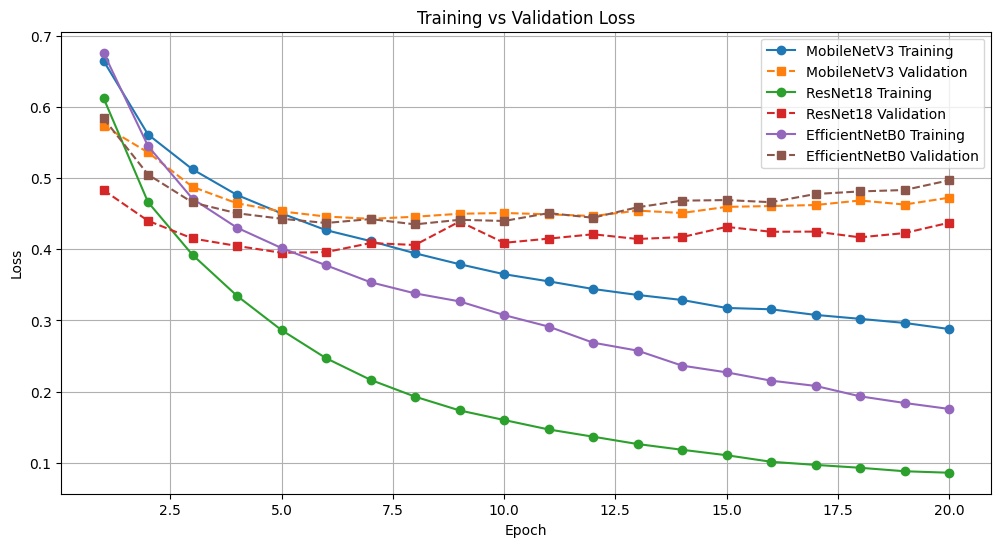

In [ ]:
plt.figure(figsize=(12, 6))

for name in model_names:

    plt.plot(
        range(1, EPOCHS + 1),
        training_history[name]["train_loss"],
        marker="o",
        label=f"{name} Training"
    )

    plt.plot(
        range(1, EPOCHS + 1),
        training_history[name]["val_loss"],
        marker="s",
        linestyle="--",
        label=f"{name} Validation"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid()
plt.show()

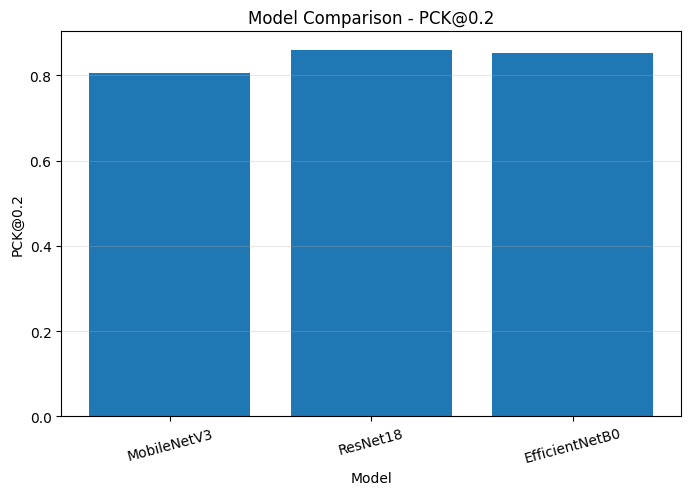

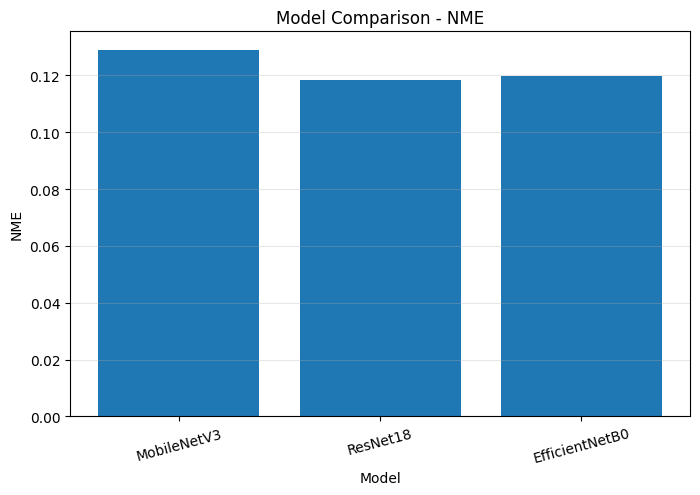

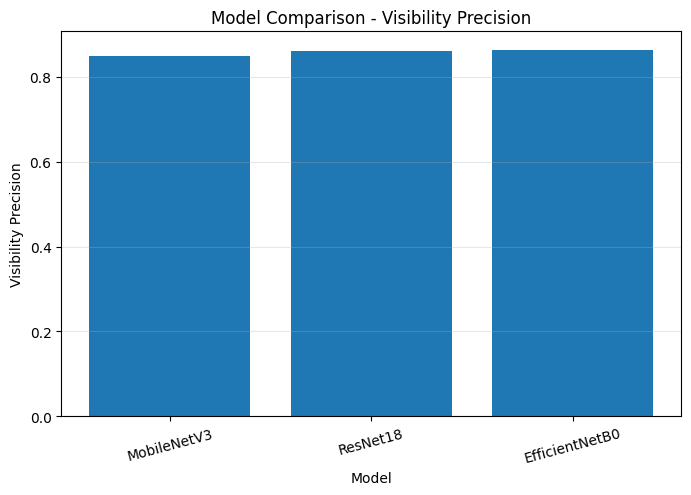

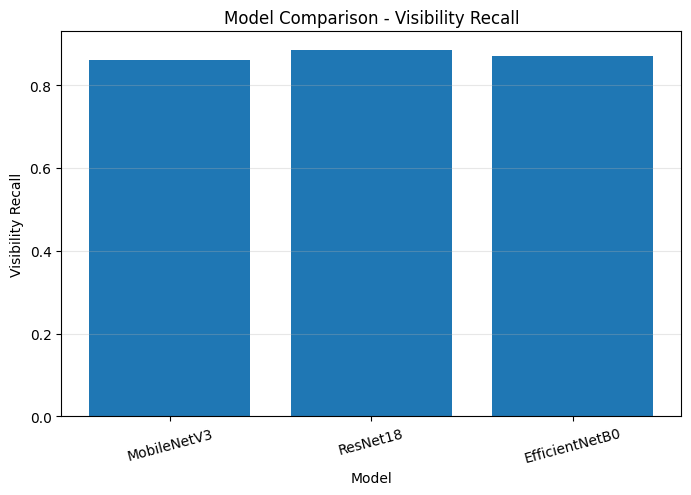

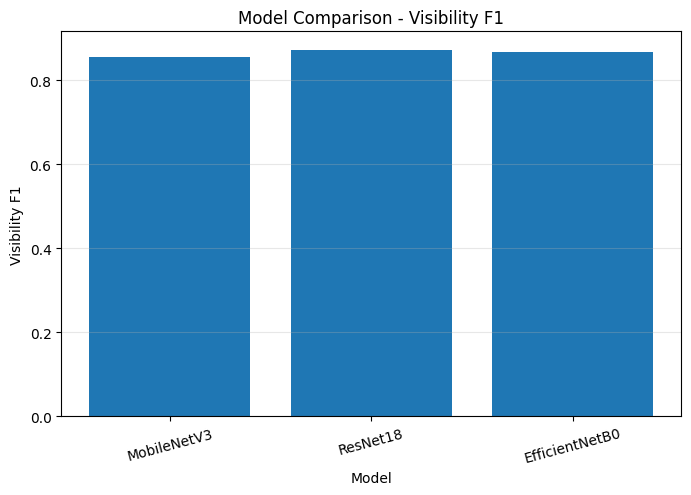

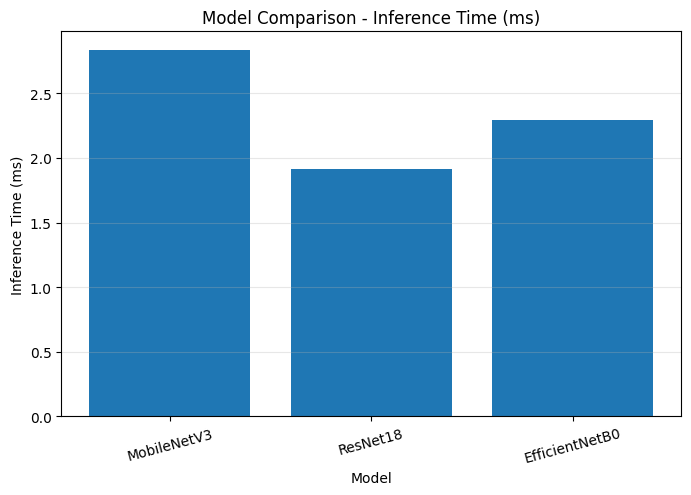

In [ ]:
metrics = [
    "PCK@0.2",
    "NME",
    "Visibility Precision",
    "Visibility Recall",
    "Visibility F1",
    "Inference Time (ms)"
]

for metric in metrics:

    plt.figure(figsize=(8, 5))

    plt.bar(results_df.index, results_df[metric])

    plt.title(f"Model Comparison - {metric}")
    plt.ylabel(metric)
    plt.xlabel("Model")
    plt.xticks(rotation=15)
    plt.grid(axis="y", alpha=0.3)

    plt.show()

In [ ]:
print("========== FINAL RESULTS ==========")

print("Best PCK:", results_df["PCK@0.2"].idxmax())
print("Lowest NME:", results_df["NME"].idxmin())
print("Best Visibility F1:",
      results_df["Visibility F1"].idxmax())
print("Fastest Inference:",
      results_df["Inference Time (ms)"].idxmin())

print("===================================")

========== FINAL RESULTS ==========
Best PCK: ResNet18
Lowest NME: ResNet18
Best Visibility F1: ResNet18
Fastest Inference: ResNet18


In [ ]:
import os

os.makedirs("final_pose_models", exist_ok=True)

for name, model in trained_models.items():

    torch.save(
        model.state_dict(),
        f"final_pose_models/{name}.pth"
    )

results_df.to_csv(
    "final_pose_models/comparison_results.csv"
)

print("All models and comparison results saved!")

All models and comparison results saved!
